# `radonika` — Interactive Laws of 2-D Stochastic Processes & Radon–Nikodym Visuals

`radonika` simulates, analyzes, and visualizes 2-D stochastic processes $(X_t, Y_t)$ alongside Radon–Nikodym likelihood-ratio processes $Z_t = \frac{d\mathbb{Q}}{d\mathbb{P}}\big|_{\mathcal{F}_t}$ and Esscher measure tilts.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import radonika as rd

---
## 1. Available 2-D Stochastic Processes

Every process in `radonika` lives in $\mathbb{R}^2$: $(X_t, Y_t)$.
* Passing a **scalar** (e.g., `mu=0.5`) applies the same parameter to both coordinates.
* Passing a **length-2 list/array** (e.g., `mu=[0.5, -0.2]`) gives each coordinate its own parameter.

### A. Continuous-Time Diffusions & Lévy Processes
| Process | Signature & Example Calls | Notes |
| :--- | :--- | :--- |
| **Brownian Motion** | `rd.bm(mu=0.0, sigma=1.0, seed=None, rho=0.0)`<br>`rd.bm(mu=[0.6, 0.2], sigma=[1.0, 1.5], rho=0.5, seed=7)` | Lévy process with MGF; supports correlation `rho` $\in (-1, 1)$ and Esscher tilting. |
| **Brownian Bridge** | `rd.bm_bridge(sigma=1.0, end=(0.0, 0.0), T=1.0, seed=None)`<br>`rd.bm_bridge(sigma=[0.8, 1.2], end=(2.0, -1.0), T=2.0)` | Pinned to `end` at horizon `T`; not a Lévy process. |
| **Poisson Process** | `rd.poisson(rate=1.0, seed=None)`<br>`rd.poisson(rate=[2.5, 6.0], seed=1)` | Integer jump subordinator; Lévy with MGF. |
| **Gamma Process** | `rd.gamma_process(a=1.0, b=1.0, seed=None)`<br>`rd.gamma_process(a=[2.0, 3.0], b=[1.5, 2.0])` | Pure-jump subordinator $X_t \sim \text{Gamma}(a t, b)$; Lévy with MGF ($\theta < b$). |
| **Cauchy Process** | `rd.cauchy_process(scale=1.0, loc=0.0, seed=None)`<br>`rd.cauchy_process(scale=[0.5, 1.2], loc=[0.1, -0.1])` | Symmetric/drifted stable Lévy process; **no MGF** (heavy tails). |
| **Discounted Stocks ($\mathbb{P}$)** | `rd.stocks(mu, sigma, r, seed=None, rho=0.0, verbose=True)`<br>`rd.stocks(mu=[0.12, 0.08], sigma=[0.25, 0.35], r=0.02, rho=0.4)` | Geometric Brownian motion in discounted units; default start `(1.0, 1.0)`. |
| **Risk-Neutral Stocks ($\mathbb{Q}$)** | `rd.stocks_neutral(mu, sigma, r, seed=None, rho=0.0, verbose=True)`<br>`rd.stocks_neutral(0.10, 0.30, 0.02)` | Discounted stock prices under the risk-neutral measure $\mathbb{Q}$. |

### B. Discrete-Time / Marginal i.i.d. Processes
| Process | Signature & Example Calls | Notes |
| :--- | :--- | :--- |
| **Normal** | `rd.normal(mean=0.0, sigma=1.0, seed=None)`<br>`rd.normal(mean=[0.0, 1.0], sigma=[1.0, 2.0])` | i.i.d. Gaussian noise at each slice. |
| **Laplace** | `rd.laplace(loc=0.0, scale=1.0, seed=None)`<br>`rd.laplace(loc=[0.0, 0.0], scale=[0.8, 1.2])` | Double-exponential tails $\propto e^{-|x-m|/b}$. |
| **Cauchy** | `rd.cauchy(loc=0.0, scale=1.0, seed=None)`<br>`rd.cauchy(loc=[0.0, 0.0], scale=[0.5, 1.0])` | Heavy-tailed marginal law (no mean/variance). |
| **Student-$t$** | `rd.student_t(df=3.0, loc=0.0, scale=1.0, seed=None)`<br>`rd.student_t(df=[1.5, 4.0], loc=0.0, scale=1.0)` | Interpolates between Cauchy (`df=1`) and Normal (`df` $\to \infty$). |
| **Exponential** | `rd.exponential(rate=1.0, seed=None)`<br>`rd.exponential(rate=[1.0, 2.5])` | Supported on $[0, \infty)^2$. |
| **Uniform** | `rd.uniform(low=0.0, high=1.0, seed=None)`<br>`rd.uniform(low=[-1.0, 0.0], high=[1.0, 2.0])` | Compactly supported on `[low, high]`. |
| **Log-Normal** | `rd.lognormal(mean=0.0, sigma=1.0, seed=None)`<br>`rd.lognormal(mean=[0.0, 0.2], sigma=[0.5, 0.8])` | $\exp(\mathcal{N}(\mu, \sigma^2))$ on $(0, \infty)^2$. |
| **Custom SciPy i.i.d.** | `rd.iid(dist, seed=None)`<br>`rd.iid([scipy.stats.gamma(2), scipy.stats.beta(2, 5)])` | Wraps any frozen `scipy.stats` distribution(s). |

---
## 2. Core Functions & Process Methods

### Simulation & Law Inspection
* `m.paths(n=20, T=1.0, steps=200, start=None, seed=None)` — Simulate `n` sample paths on `[0, T]`, returning `(times, X)`.
* `m.sample(t, n=10000, start=None, seed=None)` — Draw `n` independent samples of $(X_t, Y_t)$ at time `t`.
* `m.pdf(t, x, y, start=None)` — Closed-form joint density (or PMF for discrete laws) at time `t`.
* `m.center(t, start=None)` — Theoretical mean (or median when mean is undefined, e.g., Cauchy) at time `t`.
* `m.analyze(t=4, start=None, times=None, T=1.0, n=400, n_paths=60, seed=None, save=None, show=True)` — Static multi-slice scatter + Highest Density Region (HDR) contour evolution figure.
* `m.plot_law(start=None, time=None, time_slice=None, n=20, seed=None, ...)` — Interactive 3-D Dash + Plotly viewer showing evolving density surfaces alongside sample paths.

### Change of Measure, Esscher Tilting & Rare Events
* `m.esscher(theta)` / `m.at(theta=0.0, measure="P")` — Return the exponentially tilted process $\mathbb{Q}_\theta$ (or alternative pricing measure `"Q"`, `"Q1"`, `"Q2"` for `stocks`).
* `m.tilt(start=None, time=None, time_slice=None, n=20, theta_range=(-2.0, 2.0), ...)` — Interactive `plot_law` viewer augmented with an Esscher $\theta$ slider and drift-removal snap button $\theta^*$.
* `m.rare(K, T=1.0, start=None, n_max=100_000, seed=None, show=True)` / `rd.rare_event(...)` — Compare naive Monte Carlo vs. optimal Esscher importance sampling for estimating $\mathbb{P}(X^1_T > K)$.
* `stocks.exchange_option(T=1.0, start=None, n=400_000, seed=None)` — Prices a Margrabe exchange option $(S_1 - S_2)^+$ comparing closed-form, $\mathbb{Q}$, and stock-numeraire $\mathbb{Q}_1$.

### Likelihood-Ratio Processes (`rd.lr`)
* `z = rd.lr(p, q, seed=None)` — Construct the 1-D Radon–Nikodym derivative process $Z_t = \frac{d\mathbb{Q}}{d\mathbb{P}}\big|_{\mathcal{F}_t}$ simulated under $\mathbb{P}$ (raises `SingularMeasureError` if $\mathbb{Q} \not\ll \mathbb{P}$).
* `z.lrc(t=1.0, start=None, grid=200, show=True, save=None)` — Plot the **Likelihood-Ratio Curve**: a 2-D heatmap of $\log_{10}(q_t(x)/p_t(x))$ with the break-even contour $q_t = p_t$ (white) and 50% HDR of $\mathbb{P}$ (cyan dashed), paired with a 1-D cross-section.
* `z.summary(t=1.0, n=8000, start=None, seed=None)` — Print diagnostic metrics: $\mathbb{E}^{\mathbb{P}}[Z_t]$ (should be $\approx 1$), **Effective Sample Size (ESS)**, and estimated KL divergence rate $-\frac{1}{t}\mathbb{E}^{\mathbb{P}}[\log Z_t]$.
* `rd.ess(w)` — Compute Effective Sample Size $\frac{(\sum w_i)^2}{\sum w_i^2}$ directly for any weight vector.

---
## 3. Likelihood-Ratio Curves (`lrc`) & Diagnostics (`summary`)

### How `lrc` and `summary` Connect Geometrically
`z.lrc(t)` and `z.summary(t)` visualize and quantify the **exact same Radon–Nikodym derivative** $Z_t = \frac{d\mathbb{Q}}{d\mathbb{P}}$:

1. **White Contour ($\log_{10}(q_t/p_t) = 0 \iff q_t(x) = p_t(x)$):** The break-even boundary where both laws assign identical density.
2. **Cyan Dashed Contour (50% HDR of $\mathbb{P}$):** Where the bulk of simulated $\mathbb{P}$-samples actually land.
3. **Connecting Heatmap Colors to Effective Sample Size (`ESS`):**
   * **High ESS (Healthy Overlap):** When the cyan dashed region straddles the white contour—meaning $q_t/p_t \approx 1$ where $\mathbb{P}$ puts its mass—the importance weights $Z_t$ have low variance and `ESS` stays close to $n$.
   * **Low ESS (All-Red or All-Blue Overlap):** If the cyan 50% HDR of $\mathbb{P}$ sits entirely inside a **deep blue** region ($q_t \ll p_t$), almost all simulated $\mathbb{P}$-paths get weights $Z_t \approx 0$, while a tiny fraction of rare paths landing in the **deep red** region ($q_t \gg p_t$) carry all the mass to keep $\mathbb{E}^{\mathbb{P}}[Z_t] = 1$. Consequently, **`ESS` collapses toward $1$** (and the KL divergence rate in `summary()` spikes).

Unlike a sane human being, to be truly in the spirit of coding, we will start the numbering with **3.0** instead of **3.1**.

### 3.0 Linear Hyperplane Boundary: Brownian Motion vs. Brownian Motion (Girsanov Drift Change)
When two Brownian motions share the same covariance matrix $\Sigma$, the quadratic terms $(x - \mu t)^T \Sigma^{-1} (x - \mu t)$ cancel out in $\log(q_t(x)/p_t(x))$, reducing the likelihood ratio to an exact linear function of $(x_1, x_2)$:
$$(\mu_{\mathbb{Q}} - \mu_{\mathbb{P}})^T \Sigma^{-1} x = \text{const}$$
- **White break-even line:** A straight hyperplane bisecting the space perpendicular (in the $\Sigma^{-1}$ metric) to the drift difference $\mu_{\mathbb{Q}} - \mu_{\mathbb{P}}$.
- **Blue half-plane:** Paths drifting toward $\mu_{\mathbb{P}}$ receive weights $Z_t < 1$.
- **Red half-plane:** Paths drifting toward $\mu_{\mathbb{Q}}$ receive weights $Z_t > 1$, with the cyan 50% HDR straddling the boundary for healthy `ESS`.

Likelihood ratio (girsanov, path-level) at t=1
               t: 1
            E[Z]: 0.99909
             ESS: 3827.5
               n: 8000
     KL_rate_est: 0.37465
   KL_rate_exact: 0.38


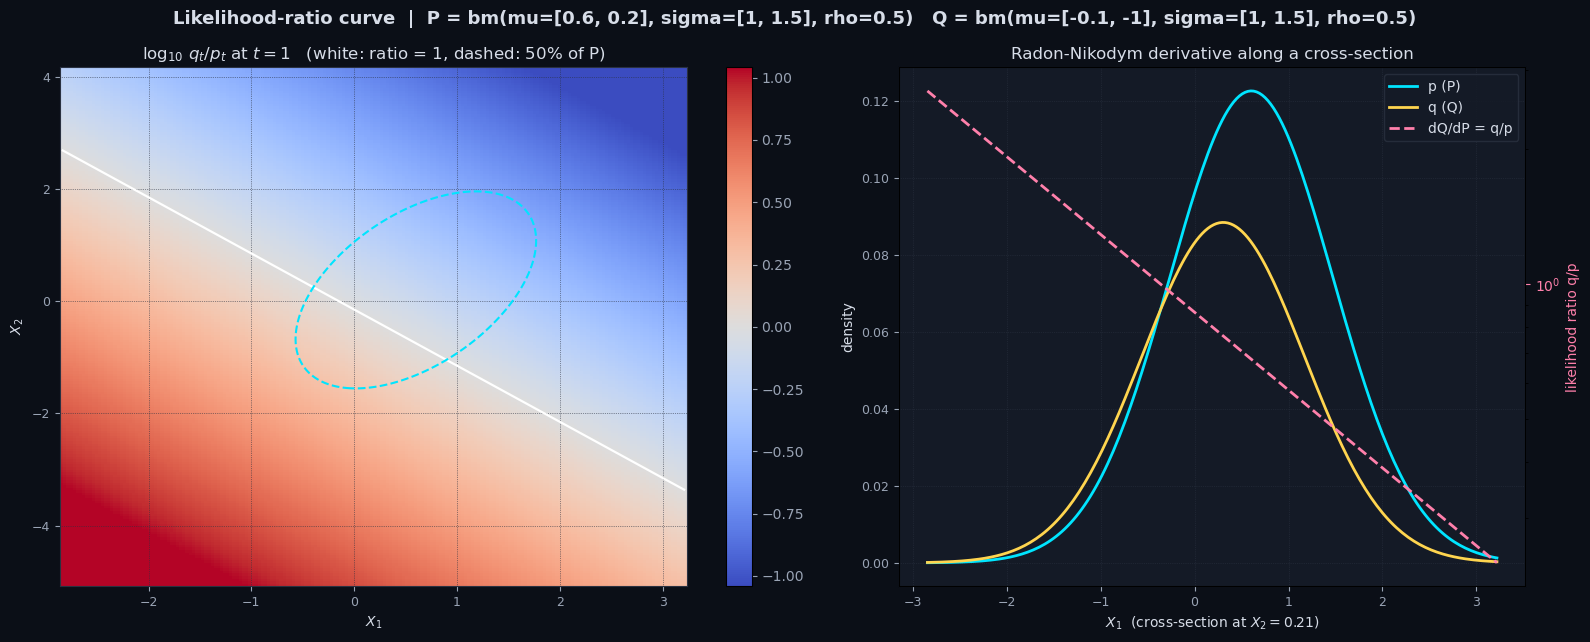

In [2]:
p_bm = rd.bm(mu=[0.6, 0.2], sigma=[1.0, 1.5], rho=0.5, seed=7)
q_bm = p_bm.at(theta=-0.4)
z_bm = rd.lr(p_bm, q_bm)
z_bm.summary(t=1.0)
fig = z_bm.lrc(t=1.0)

**Remark:** When comparing two Brownian motions with identical covariance, quadratic terms cancel and the white boundary is a straight line. Mixing different tail behaviors, correlations, or support geometries produces rich non-linear boundaries.

Also notice the cyan dashed curve: it does contain some of the red tints too, so Effective Sample Size shouldn't be low. As the plot suggests, `ESS` is indeed showing $3827.5$ out of $8000$ paths. Now we will look at a few plots where there is almost no overlap at all. Note the `ESS` value for the next few plots.

### 3.1 Four-Petal Clover: Normal vs. Laplace
Comparing Gaussian decay ($\propto e^{-x^2/2}$) against Laplace decay ($\propto e^{-|x|}$) yields $\frac{1}{2}(x_1^2+x_2^2) - (|x_1|+|x_2|) = \text{const}$, forming four intersecting circles centered at $(\pm 1, \pm 1)$:
* **Center diamond (Red):** Laplace has a sharper spike at $(0,0)$ than Normal.
* **Four petals (Blue):** Normal has broader shoulder mass around $|x| \approx 1$.
* **Outer field (Red):** Laplace's exponential tails dominate Normal's Gaussian tails everywhere outside.

Likelihood ratio (iid, path-level) at t=2
               t: 2
            E[Z]: 4.2165e-09
             ESS: 1.1547
               n: 8000
     KL_rate_est: 17.262


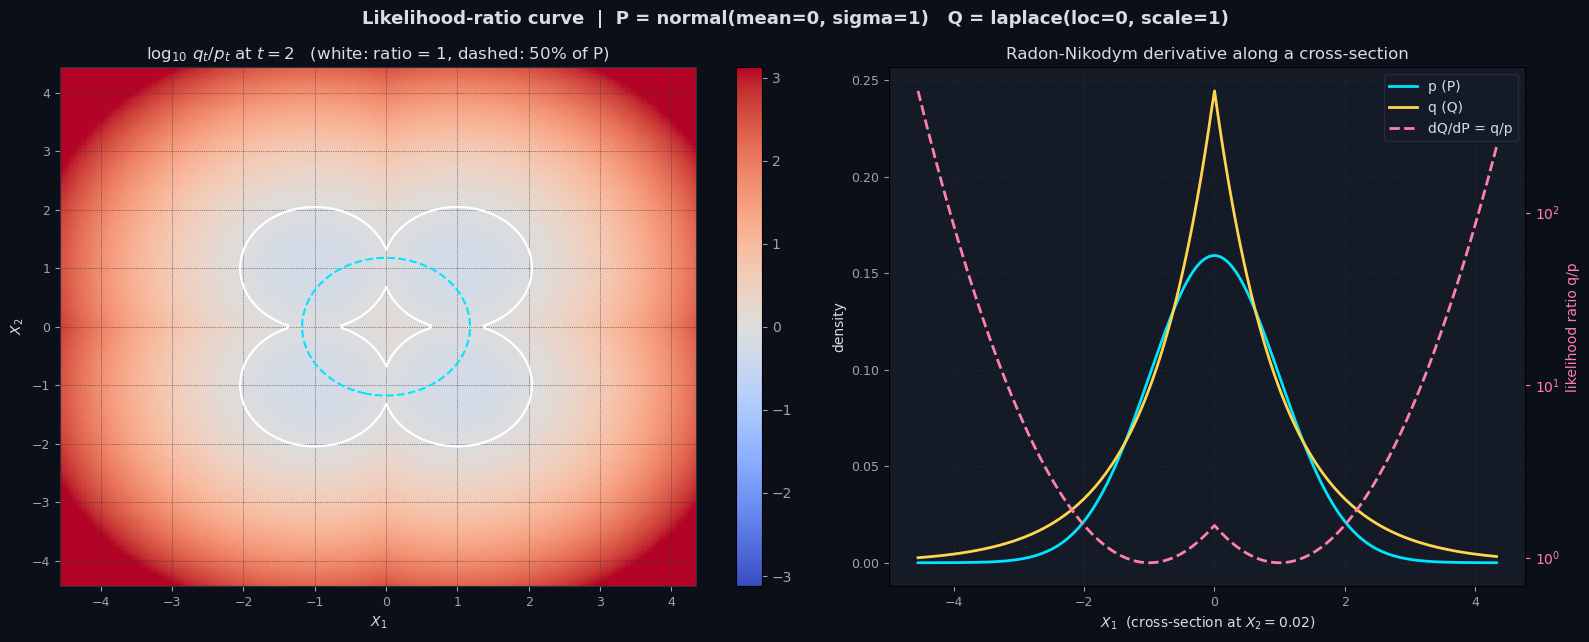

In [3]:
z_clover = rd.lr(rd.normal(0, 1, seed=1), rd.laplace(0, 1, seed=1))
z_clover.summary(t=2.0)
fig = z_clover.lrc(t=2.0);

### 3.2 Concentric Target Ring: Normal vs. Cauchy
Cauchy has polynomial heavy tails while Normal is tightly concentrated, producing a circular break-even ring where $\mathbb{P}$ dominates inside and $\mathbb{Q}$ explodes outside.

Likelihood ratio (iid, path-level) at t=1
               t: 1
            E[Z]: 4.6839e-87
             ESS: 2.2622
               n: 8000
     KL_rate_est: 267.02


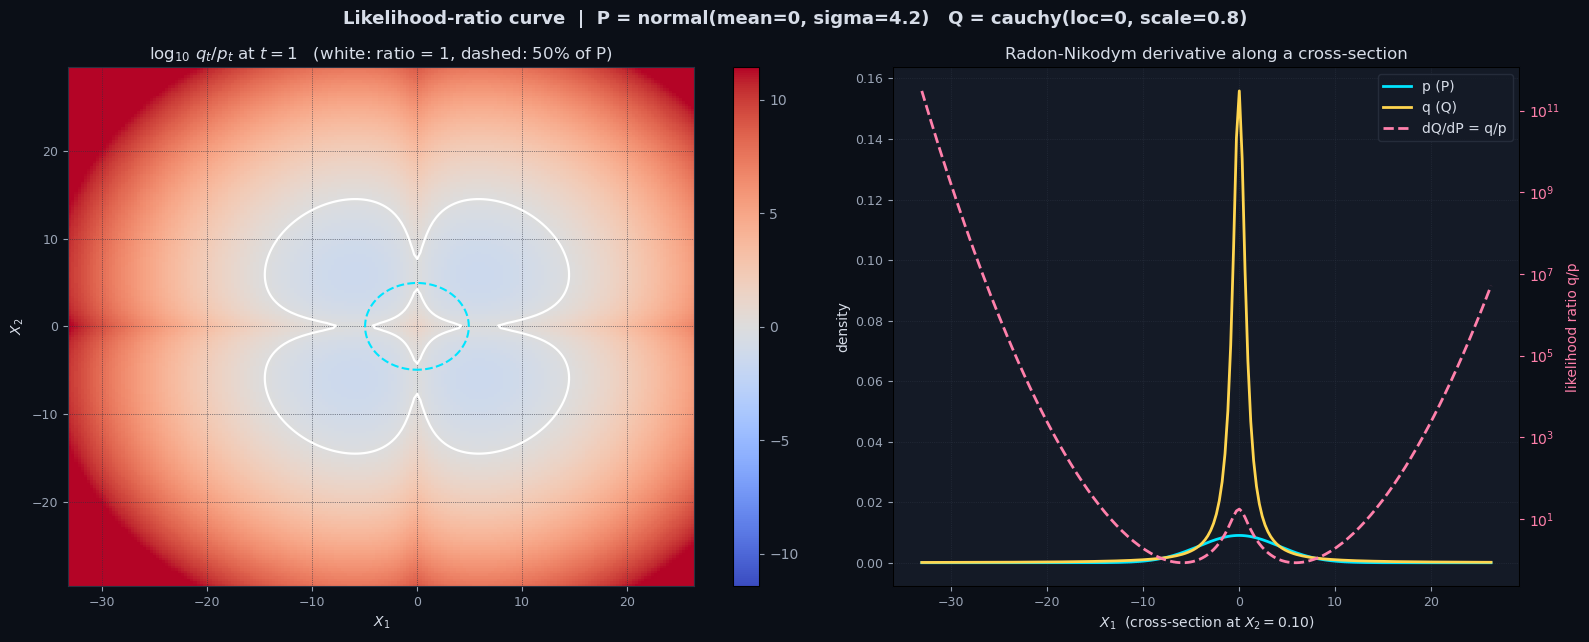

In [4]:
z_ring = rd.lr(rd.normal(0, 4.2, seed=1), rd.cauchy(0, 0.8, seed=1))
z_ring.summary(t=1.0)
fig = z_ring.lrc(t=1.0)

Likelihood ratio (iid, path-level) at t=1
               t: 1
            E[Z]: 5.7846e-145
             ESS: 1.4027
               n: 8000
     KL_rate_est: 416.21


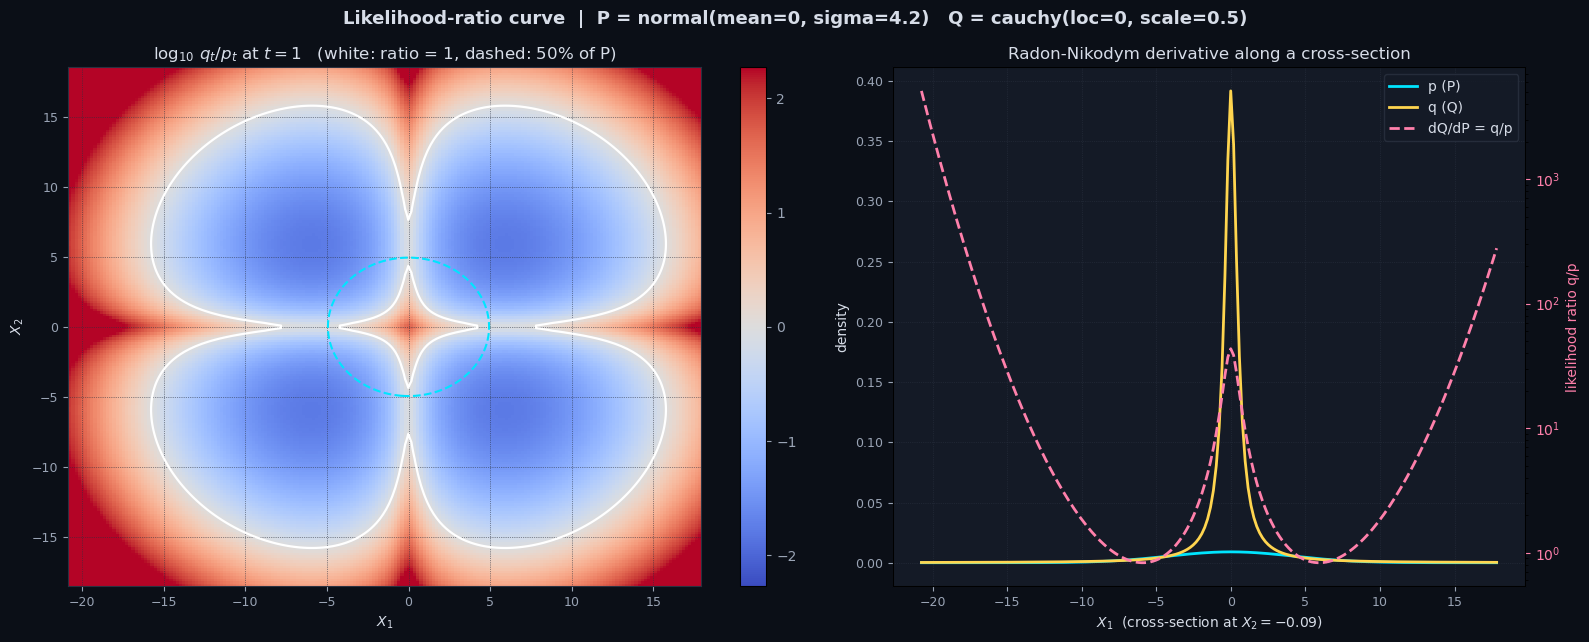

In [5]:
z_ring = rd.lr(rd.normal(0, 4.2, seed=1), rd.cauchy(0, 0.5, seed=1)) #change in cauchy from 0.1 to 2 
z_ring.summary(t=1.0)
fig = z_ring.lrc(t=1.0)

### 3.3 Hyperbolic Saddle / Crossed Blades: Asymmetric Normal vs. Laplace
Giving $X_1$ and $X_2$ opposing scales breaks rotational symmetry and stretches the clover into hyperbolic blades.

Likelihood ratio (iid, path-level) at t=1
               t: 1
            E[Z]: 9.4444e-56
             ESS: 1.133
               n: 8000
     KL_rate_est: 172.44


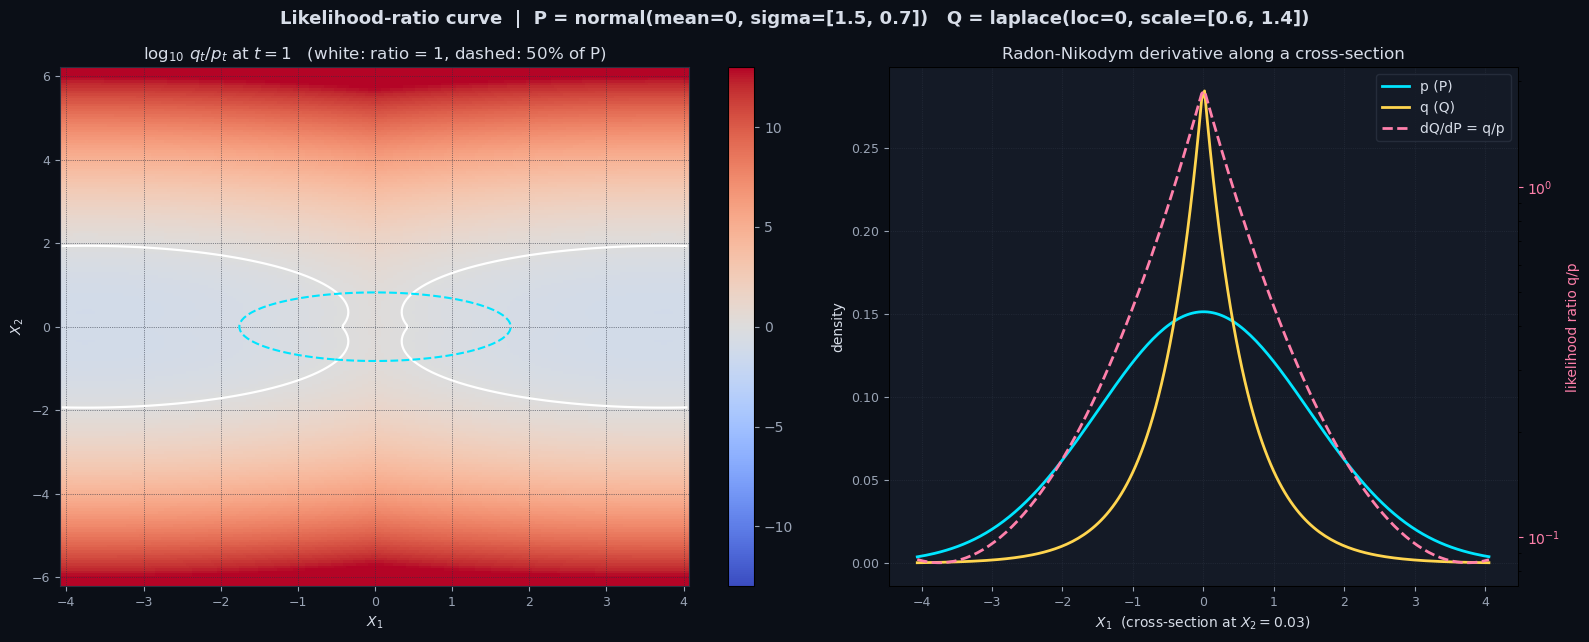

In [6]:
p_asym = rd.normal(mean=[0.0, 0.0], sigma=[1.5, 0.7], seed=2)
q_asym = rd.laplace(loc=[0.0, 0.0], scale=[0.6, 1.4], seed=2)
z_saddle = rd.lr(p_asym, q_asym)
z_saddle.summary(t=1.0)
fig = z_saddle.lrc(t=1.0)

### 3.4 Asymmetric Crescent: Gamma Process vs. Log-Normal
Both processes live strictly on the positive quadrant $(0, \infty)^2$, bending their likelihood-ratio boundary into a curved crescent.

Likelihood ratio (marginal, marginal E[Z|X_t]) at t=2
               t: 2
            E[Z]: 1.0284
             ESS: 790.66
               n: 8000
     KL_rate_est: 0.62269


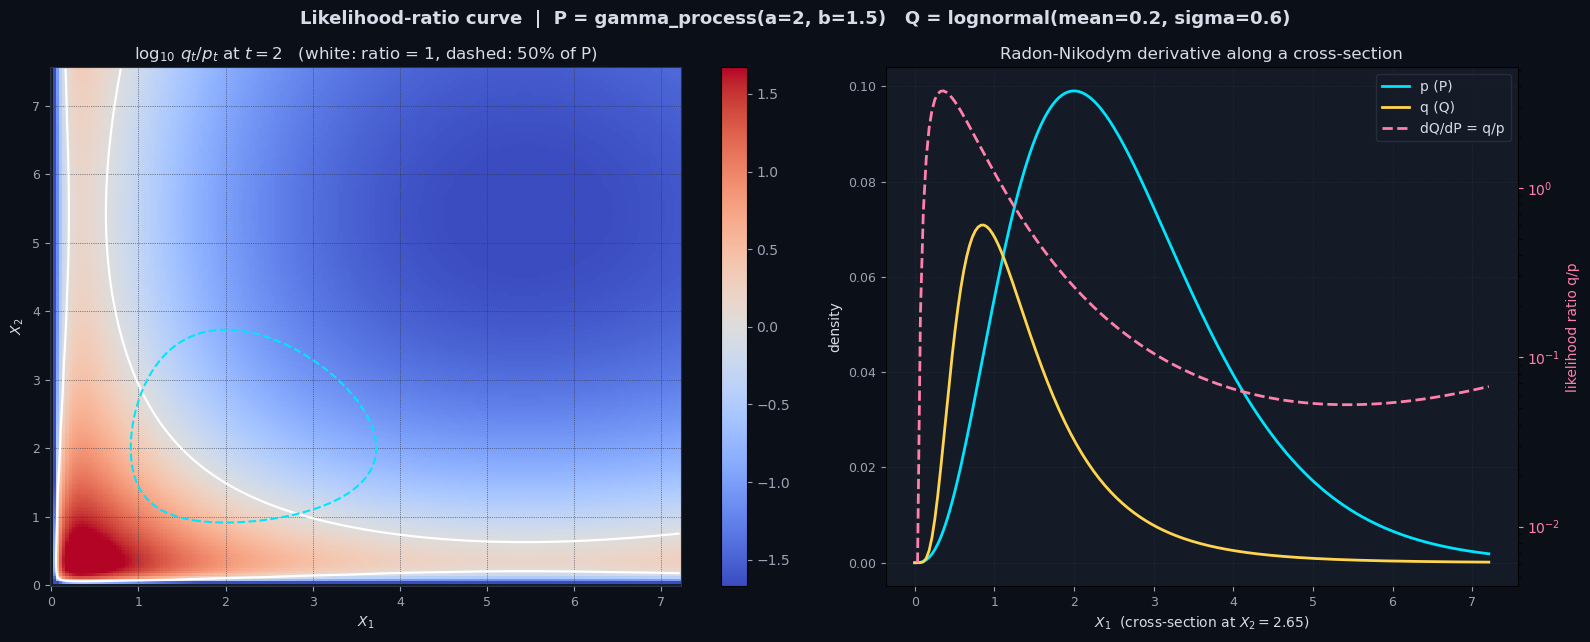

In [7]:
p_gamma = rd.gamma_process(a=[2.0, 2.0], b=[1.5, 1.5], seed=3)
q_logn  = rd.lognormal(mean=[0.2, 0.2], sigma=[0.6, 0.6], seed=3)
z_crescent = rd.lr(p_gamma, q_logn)
z_crescent.summary(t=2.0)
fig = z_crescent.lrc(t=2.0)

Note that this is the first plot in a while where we have a healthy overlap: $50\%$ of the paths are landing inside the cyan contour, which overlaps both red and blue regions, and as expected `ESS` is $790$.

### 3.5 Rounded Superellipse / Diamond: Student-$t$ vs. Normal
A heavy-tailed Student-$t$ (`df=1.5`) compared against a broader Normal creates a smooth rounded-diamond transition zone.

Likelihood ratio (iid, path-level) at t=1
               t: 1
            E[Z]: 3.1027e-59
             ESS: 1
               n: 8000
     KL_rate_est: 679.62


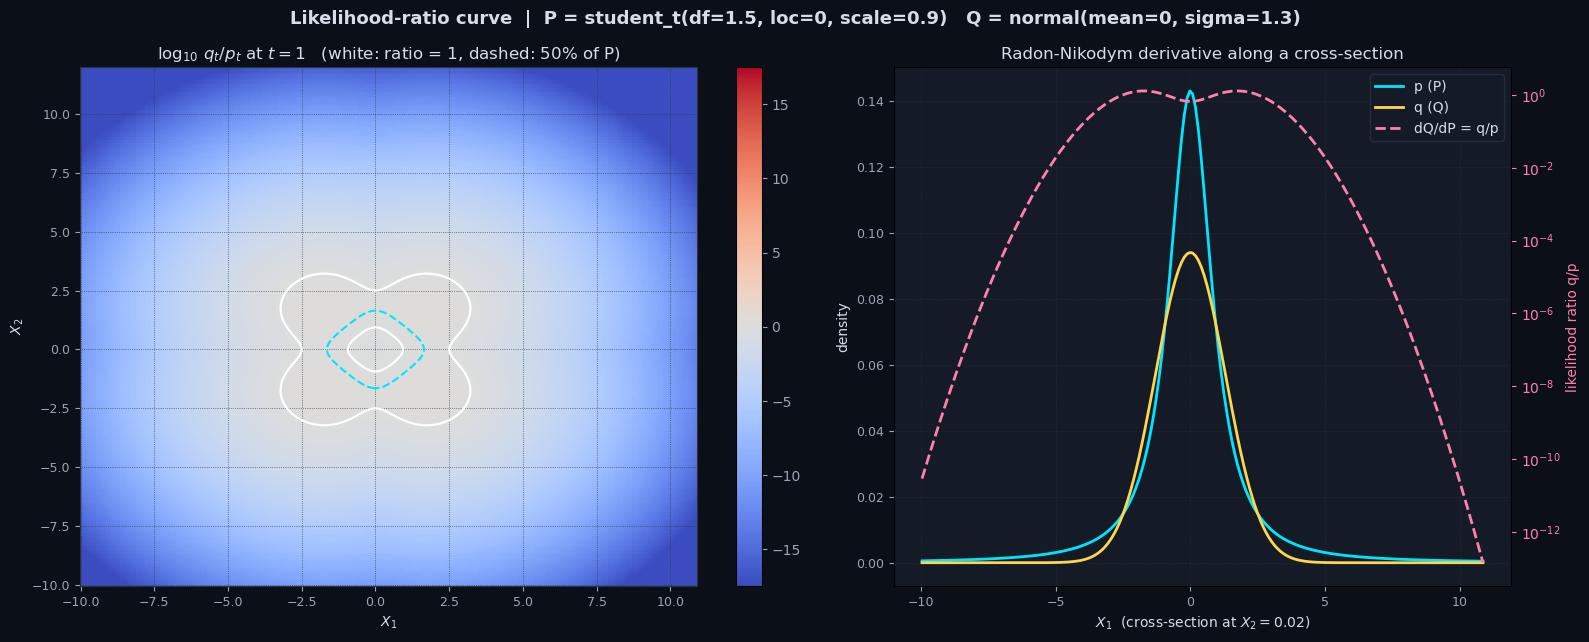

In [8]:
z_diamond = rd.lr(rd.student_t(df=1.5, loc=0, scale=0.9, seed=4), rd.normal(0, 1.3, seed=4))
z_diamond.summary(t=1.0)
fig = z_diamond.lrc(t=1.0)

### 3.6 Off-Center Tilted Eclipse: Correlated Brownian Motion vs. Laplace
A positively correlated Brownian motion (`rho=0.75`) has tilted elliptical contours slicing across an axis-aligned Laplace diamond.

Likelihood ratio (marginal, marginal E[Z|X_t]) at t=1.5
               t: 1.5
            E[Z]: 0.99219
             ESS: 427.42
               n: 8000
     KL_rate_est: 0.47515


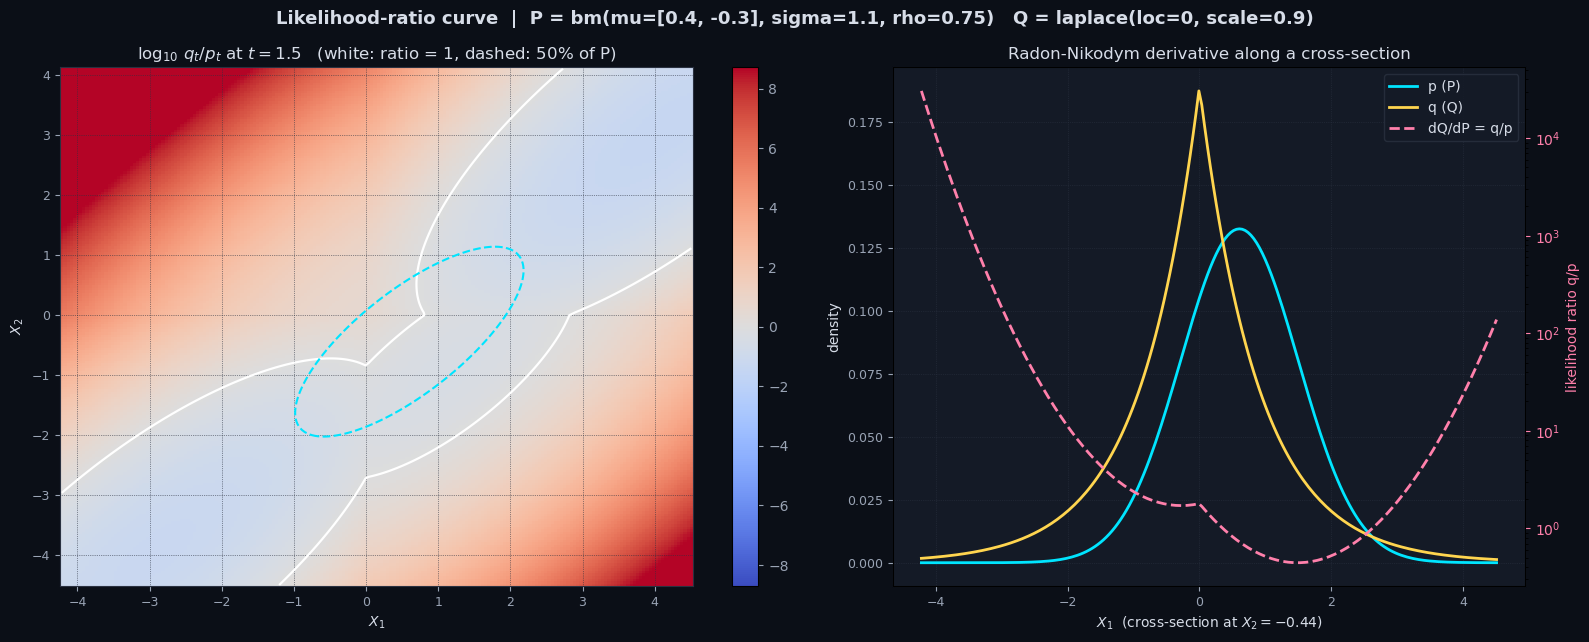

In [9]:
p_corr = rd.bm(mu=[0.4, -0.3], sigma=[1.1, 1.1], rho=0.75, seed=5)
q_lap  = rd.laplace(loc=[0.0, 0.0], scale=[0.9, 0.9], seed=5)
z_eclipse = rd.lr(p_corr, q_lap)
z_eclipse.summary(t=1.5)
fig = z_eclipse.lrc(t=1.5)

### 3.7 Discrete Lattice Stepping: Skewed 2-D Poisson Processes
Comparing two 2-D Poisson processes with swapped coordinate intensities (`[2.0, 6.0]` vs. `[6.0, 2.0]`) produces stepped diagonal bands across integer jump counts, and notice how a larger divergence lowers `ESS`.

Likelihood ratio (poisson, path-level) at t=2
               t: 2
            E[Z]: 0.74757
             ESS: 5.8427
               n: 8000
     KL_rate_est: 4.4114


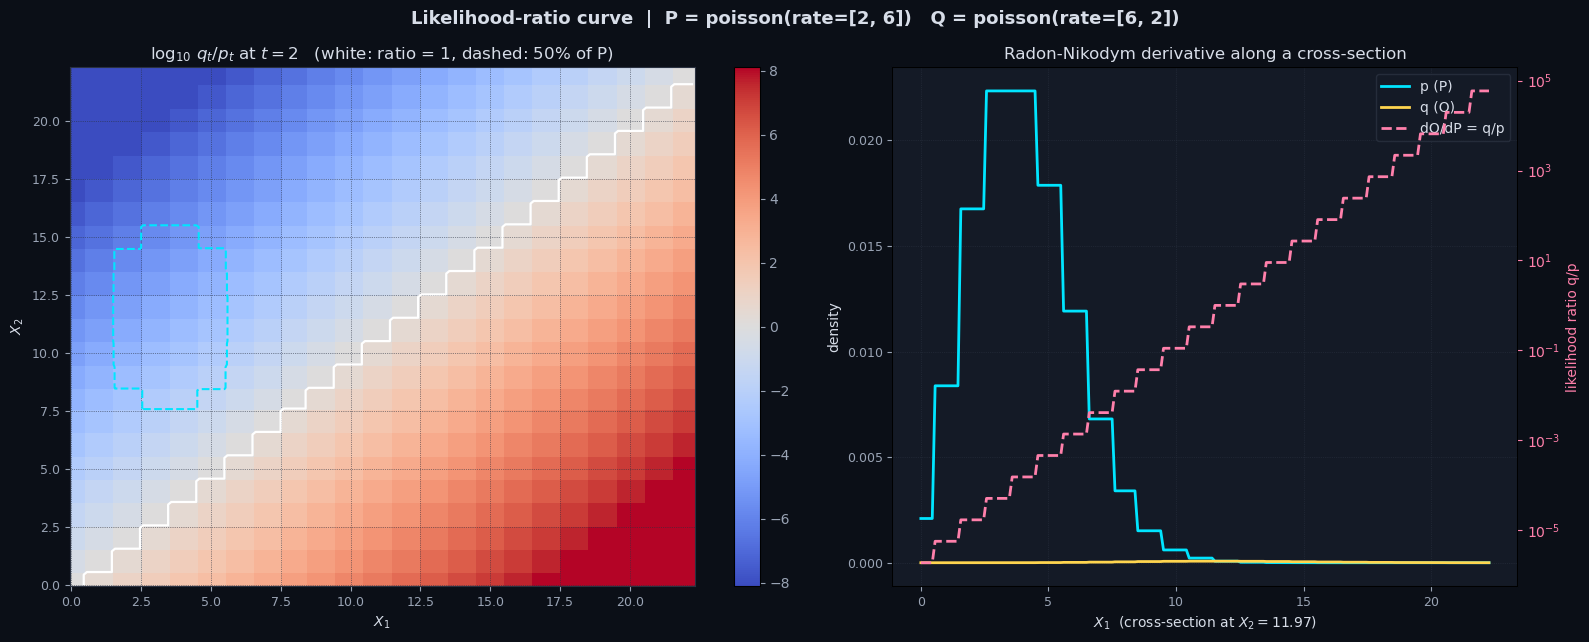

In [10]:
z_poisson = rd.lr(rd.poisson(rate=[2.0, 6.0], seed=6), rd.poisson(rate=[6.0, 2.0], seed=6))
z_poisson.summary(t=2.0)
fig = z_poisson.lrc(t=2.0)

### 3.8 Low-ESS Regime: Strongly Shifted Measures
When $\mathbb{P}$ and $\mathbb{Q}$ put their probability mass far apart, the 50% HDR of $\mathbb{P}$ (cyan loop) lies entirely inside the deep-blue tail of $\mathbb{Q}$, causing `ESS` to drop sharply toward 1. This is like the previous `bm` vs. `bm` example, but here one of the means is $\mu$ while the other is $-\mu$.

Likelihood ratio (girsanov, path-level) at t=2
               t: 2
            E[Z]: 0.036159
             ESS: 3.7072
               n: 8000
     KL_rate_est: 9.0123
   KL_rate_exact: 9


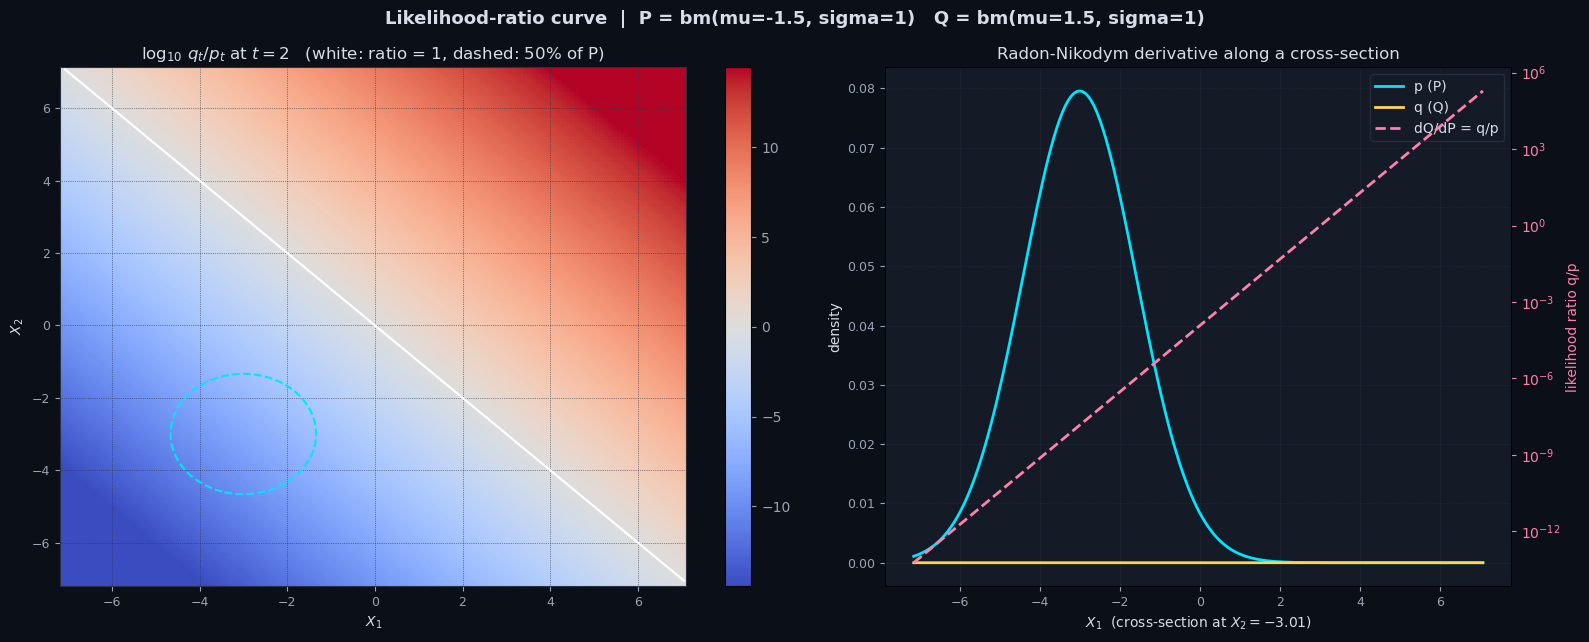

In [11]:
z_low_ess = rd.lr(rd.bm(mu=[-1.5, -1.5], sigma=1.0, seed=7), rd.bm(mu=[1.5, 1.5], sigma=1.0, seed=7))
z_low_ess.summary(t=2.0)
fig = z_low_ess.lrc(t=2.0)

---
## 4. Multi-Slice Law Evolution (`analyze`)

`m.analyze(t=4, ...)` renders a two-layer static report:
* **Top row:** Sample paths up to slice time $t_j$ overlaid on a cloud of terminal samples and the theoretical center (white-ringed dot). It was a deliberate design choice I made to keep at most $6$ panels on the top, i.e., `t<=6`.
* **Bottom row:** **Contour Evolution** showing the 50% (thick) and 90% (thin) Highest Density Regions expanding, drifting, or contracting over time. The contours are already color-coded to ensure immediate detection of which contour belongs to which spread.

### 4.1 2-D Discrete Poisson Process
Watch integer lattice clusters step upward and rightward as jump counts accumulate across $t \in \{0.5, 1.0, 1.5, 2.0\}$.

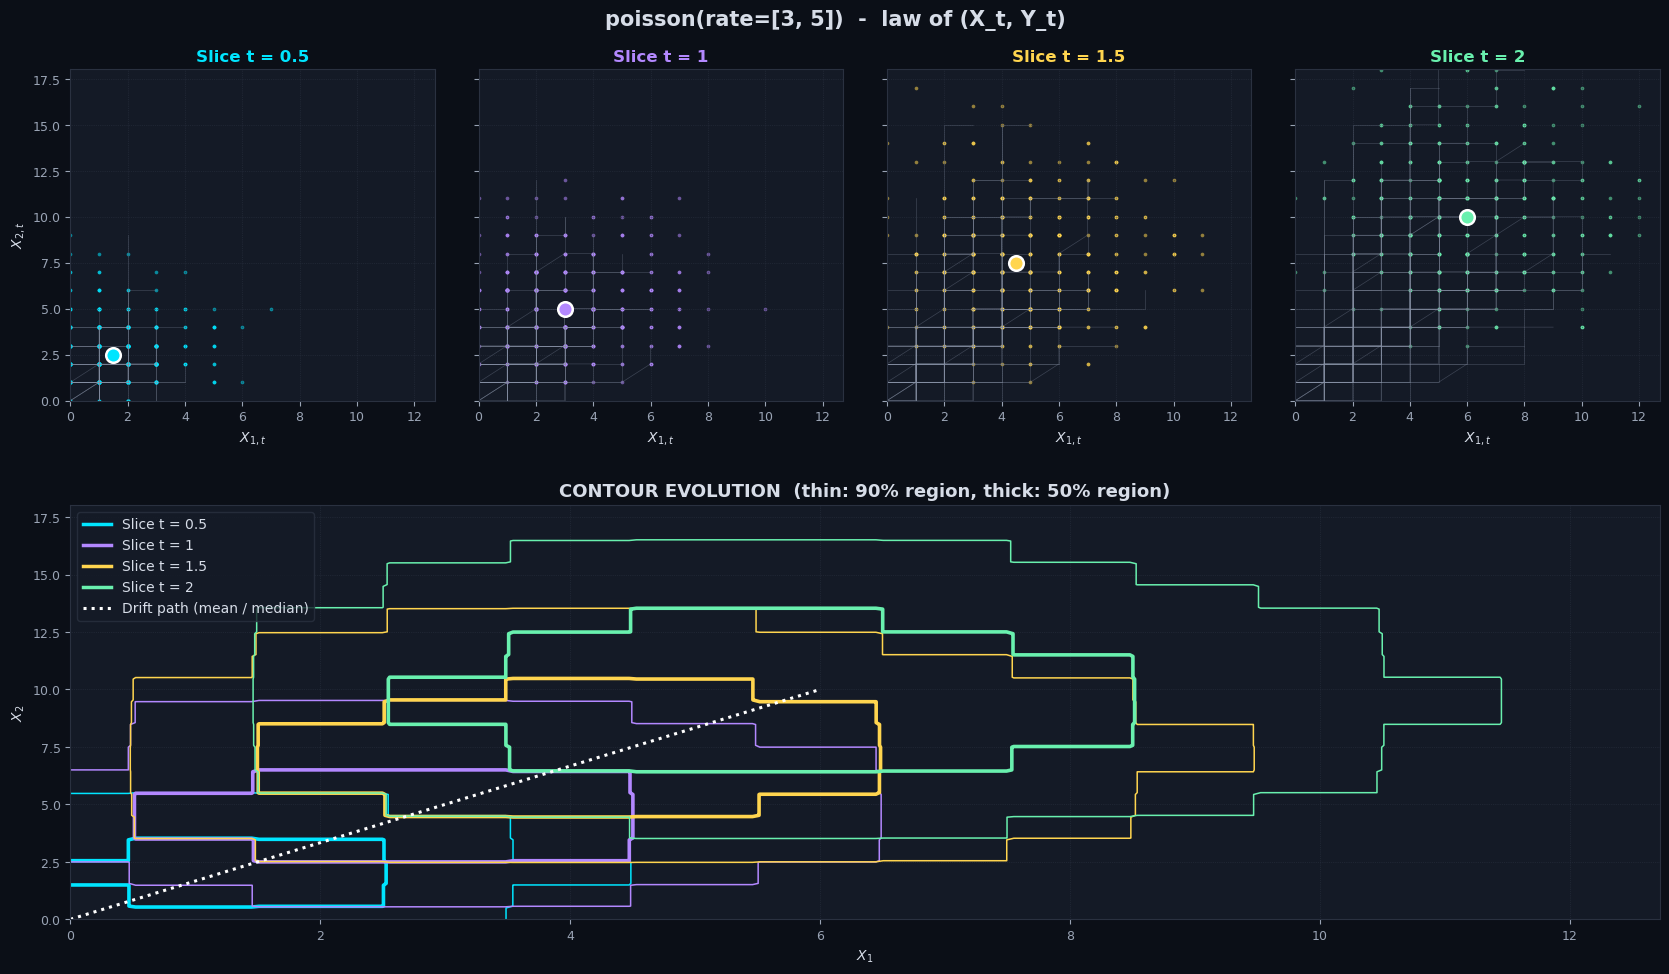

In [12]:
m_pois = rd.poisson(rate=[3.0, 5.0], seed=10)
fig = m_pois.analyze(t=4, T=2.0, seed=10)

### 4.2 Correlated Discounted Stocks (`rho = 0.75` & `rho = -0.75`)
Notice the log-normal spread. As time advances, the HDR contours stretch along the diagonal and develop heavy upper-right skewness. This is natural in the case of positive correlation between the two coordinates. We will see the negative-correlation case after this to highlight the difference.

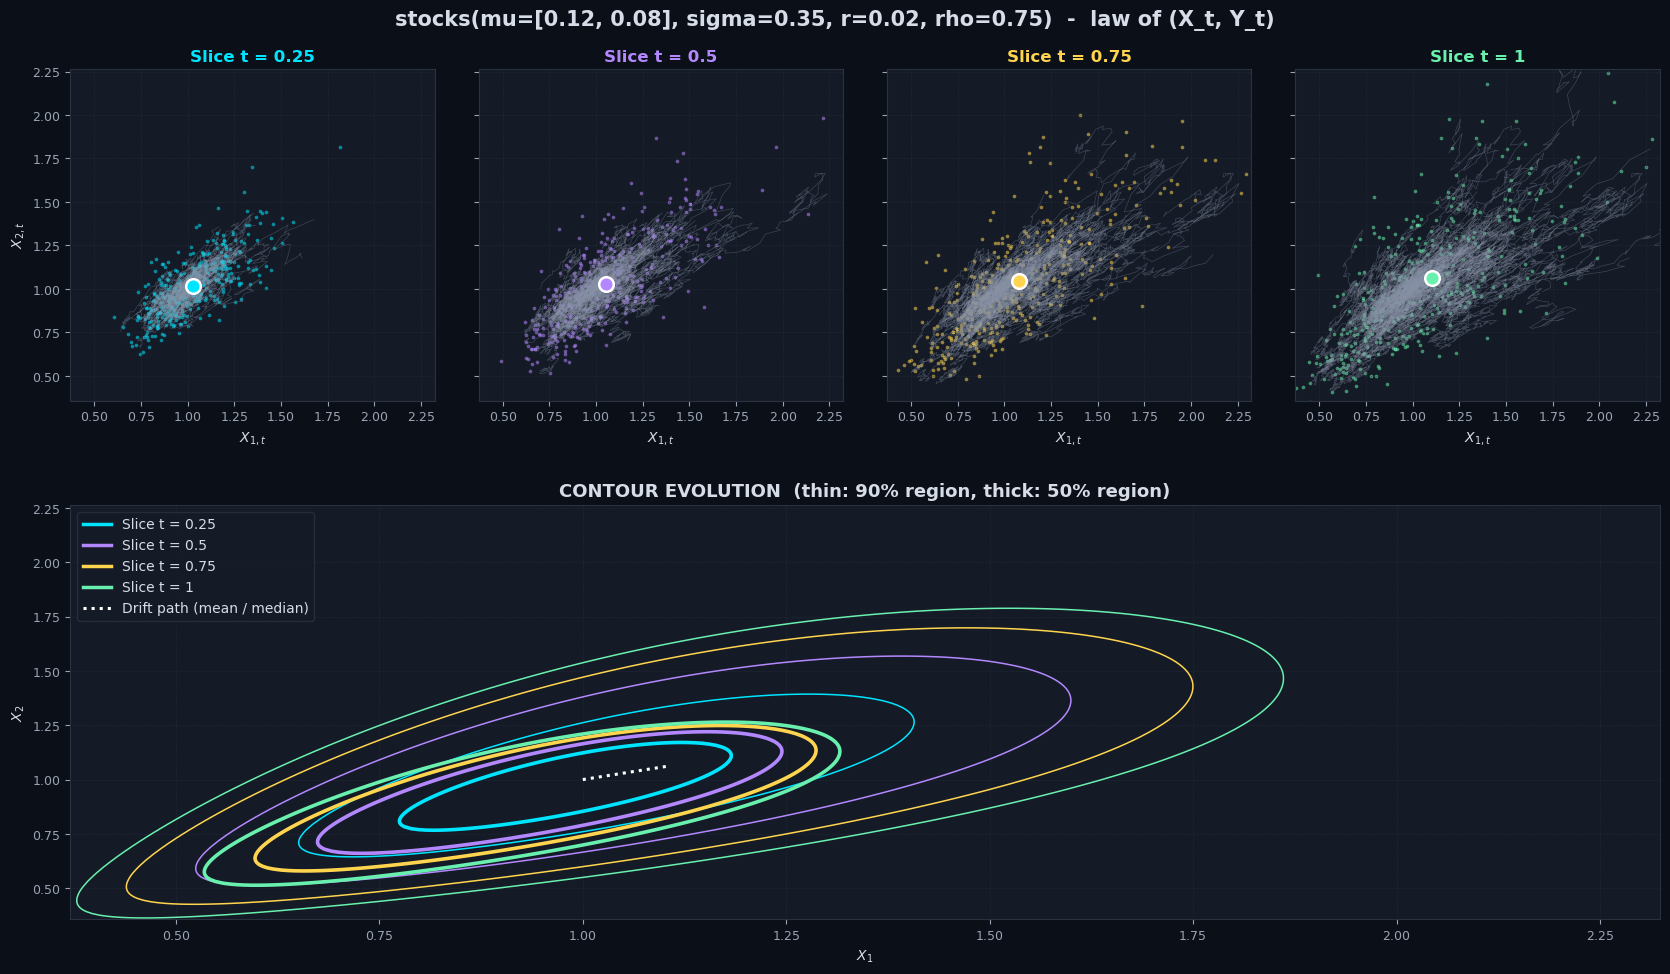

In [13]:
m_stock = rd.stocks(mu=[0.12, 0.08], sigma=[0.35, 0.35], r=0.02, rho=0.75, seed=1, verbose=False)
fig = m_stock.analyze(t=4, T=1.0);

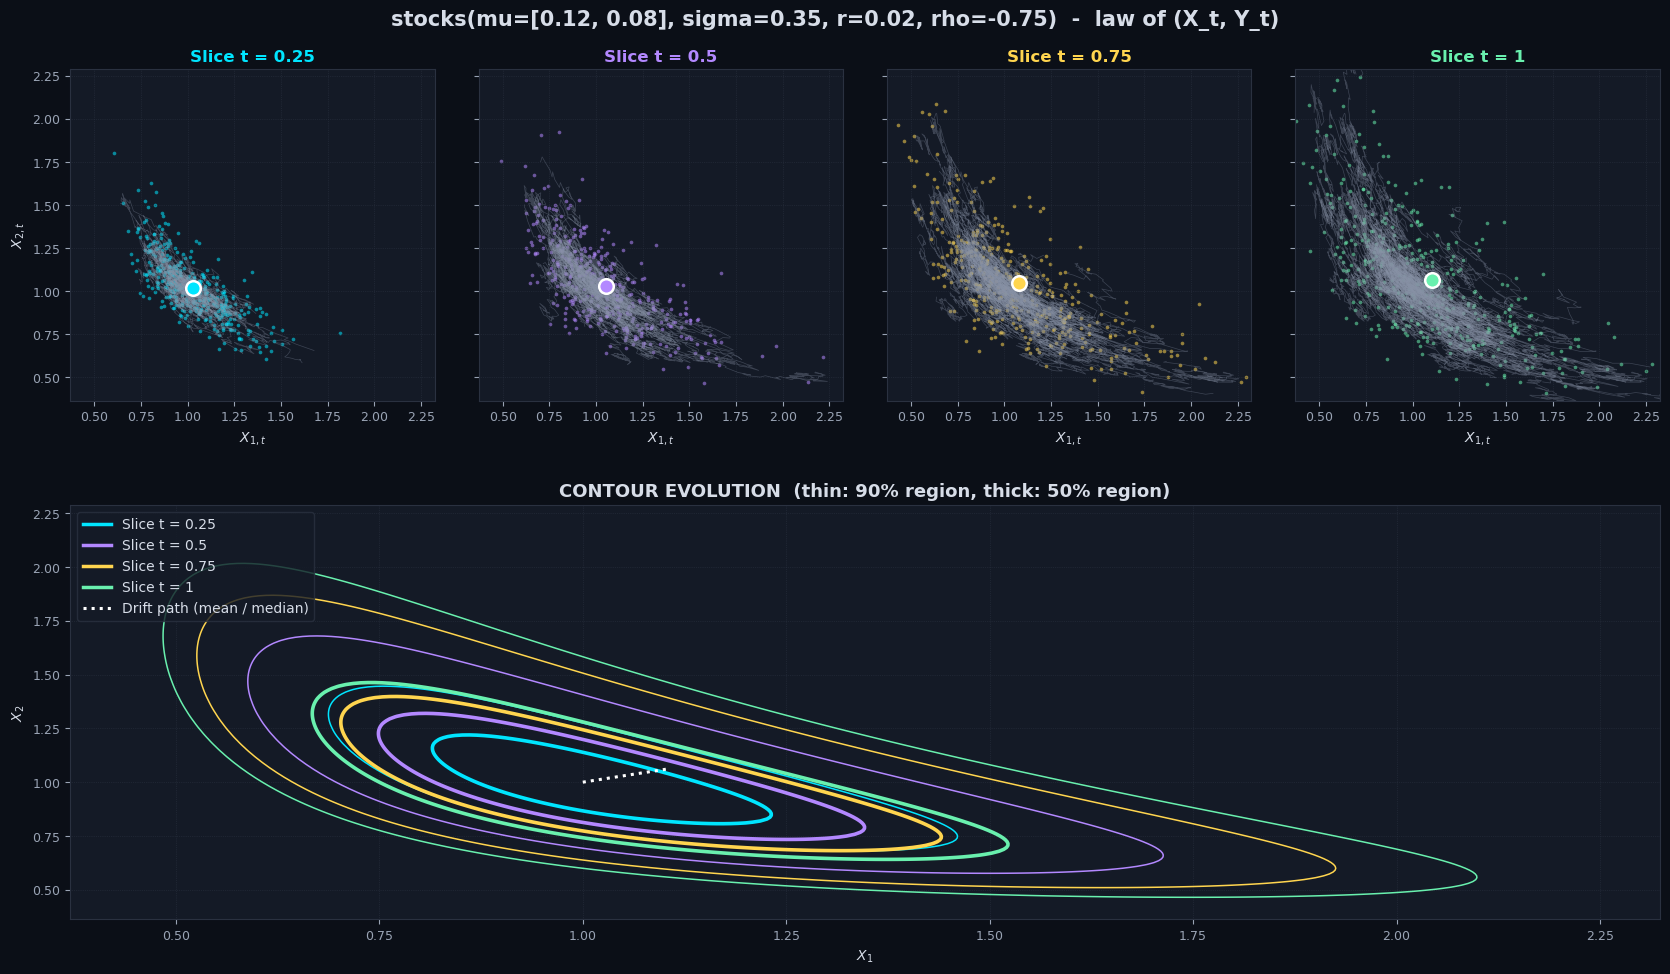

In [14]:
m_stock = rd.stocks(mu=[0.12, 0.08], sigma=[0.35, 0.35], r=0.02, rho=-0.75, seed=1, verbose=False)
fig = m_stock.analyze(t=4, T=1.0);

Negative correlation will give us ellipses with the major principal axis along $(-1,1)$. But now, since the parameters of the two stock prices are different, they will not be symmetric ellipses; they will end up forming a much different structure. This new structure will still show the "when Stock 1 booms ($X_1$ becomes large), Stock 2 crashes toward $0$ ($X_2 \to 0$), and vice versa" relationship.

### 4.3 Brownian Bridge (Expansion Followed by Pinning at $T$)
Unlike free Brownian motion, a Brownian bridge expands until $t = T/2$ and then contracts back onto its terminal target `end = (2.5, -1.5)` at $t = T$. Notice the yellow contour (corresponding to half-time) has maximum spread. Also note there is no spread corresponding to $t=2$ since the entire process has collapsed back to this point.

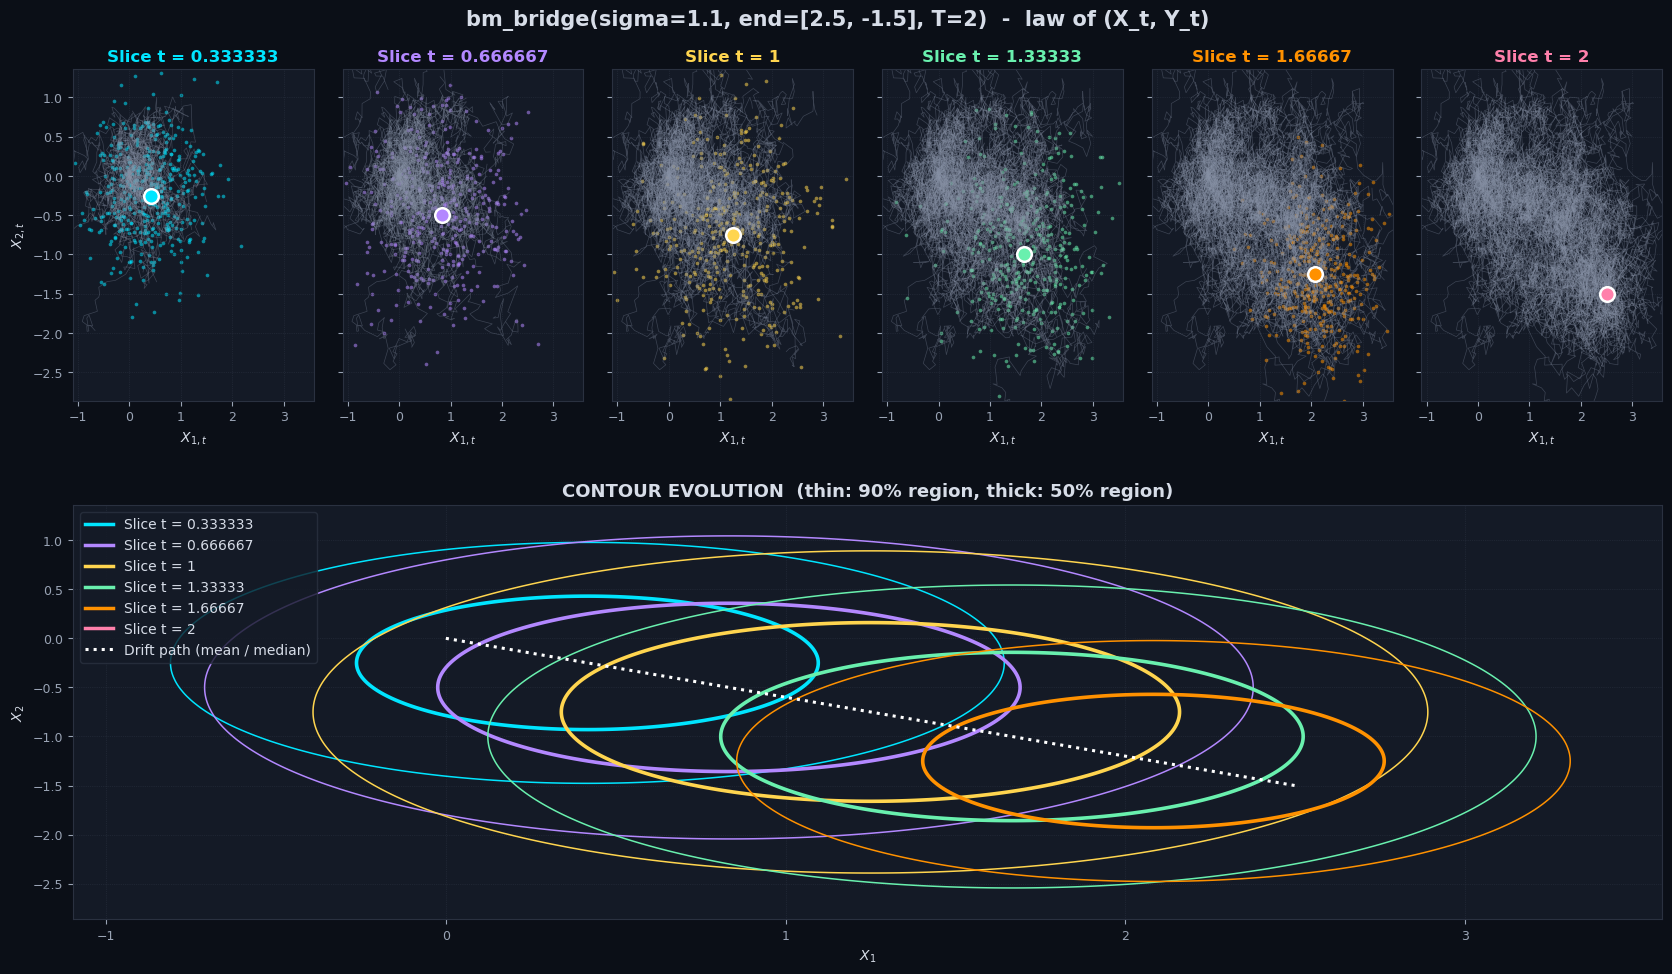

In [15]:
m_bridge = rd.bm_bridge(sigma=[1.1, 1.1], end=(2.5, -1.5), T=2.0, seed=12)
fig = m_bridge.analyze(t=6, T=2.0, seed=12)

### 4.4 2-D Gamma Subordinator (Monotone Positive Drift)
A pure-jump Gamma process starts at $(0,0)$ and moves strictly into the positive quadrant with right-skewed gamma contours.

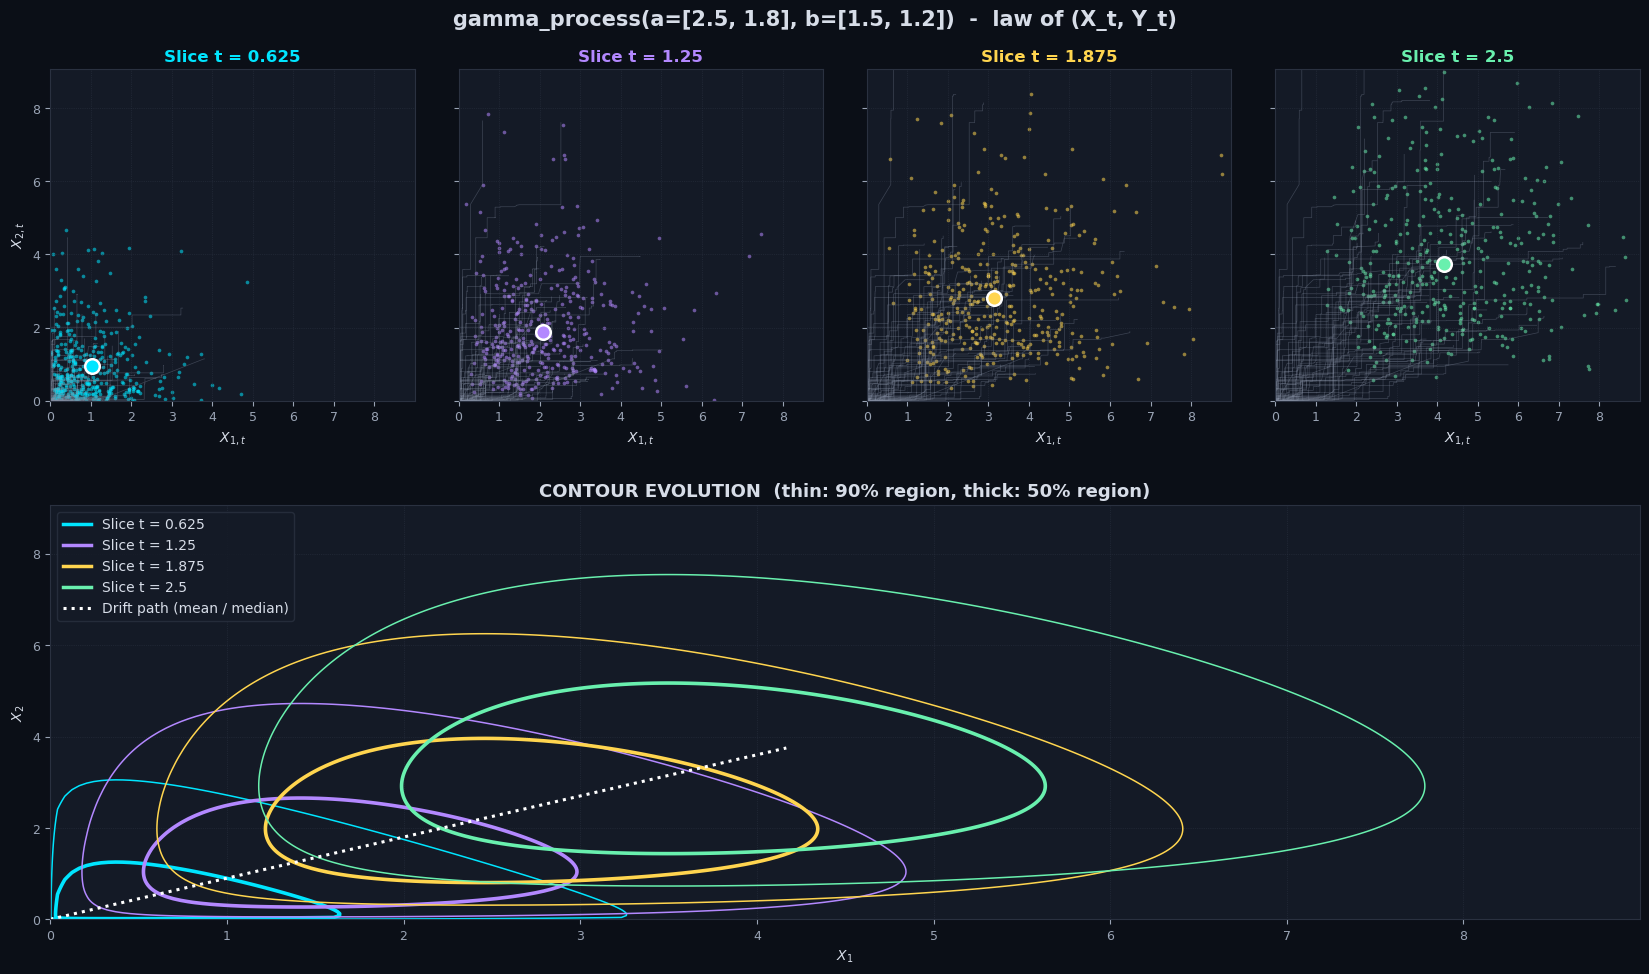

In [16]:
m_gamma = rd.gamma_process(a=[2.5, 1.8], b=[1.5, 1.2], seed=13)
fig = m_gamma.analyze(t=4, T=2.5, seed=13)

### 4.5 Negatively Correlated Drifted Brownian Motion (`rho = -0.8`)
Strong negative correlation tilts the Gaussian ellipses along the anti-diagonal while drifting toward the upper-left.

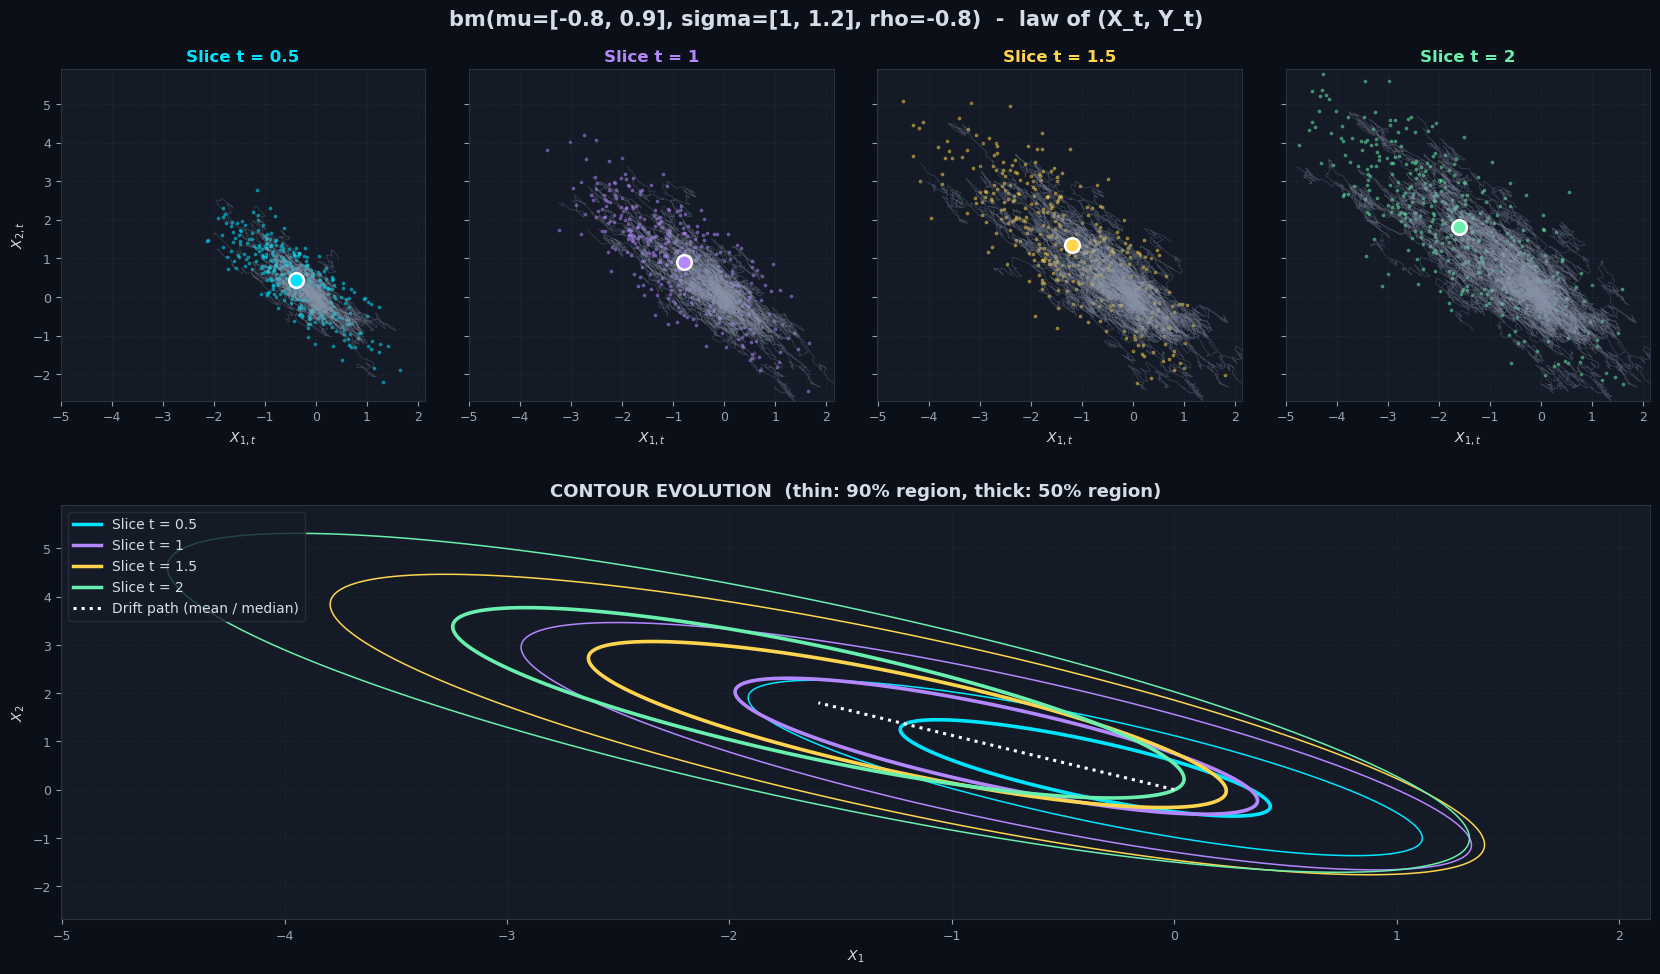

In [17]:
m_bm_neg = rd.bm(mu=[-0.8, 0.9], sigma=[1.0, 1.2], rho=-0.8, seed=14)
fig = m_bm_neg.analyze(t=4, T=2.0, seed=14)

### 4.6 Heavy-Tailed Cauchy Process (`cauchy_process`)
Because Cauchy increments have infinite variance, occasional large jumps scatter sample paths far outside the tight central median contours.

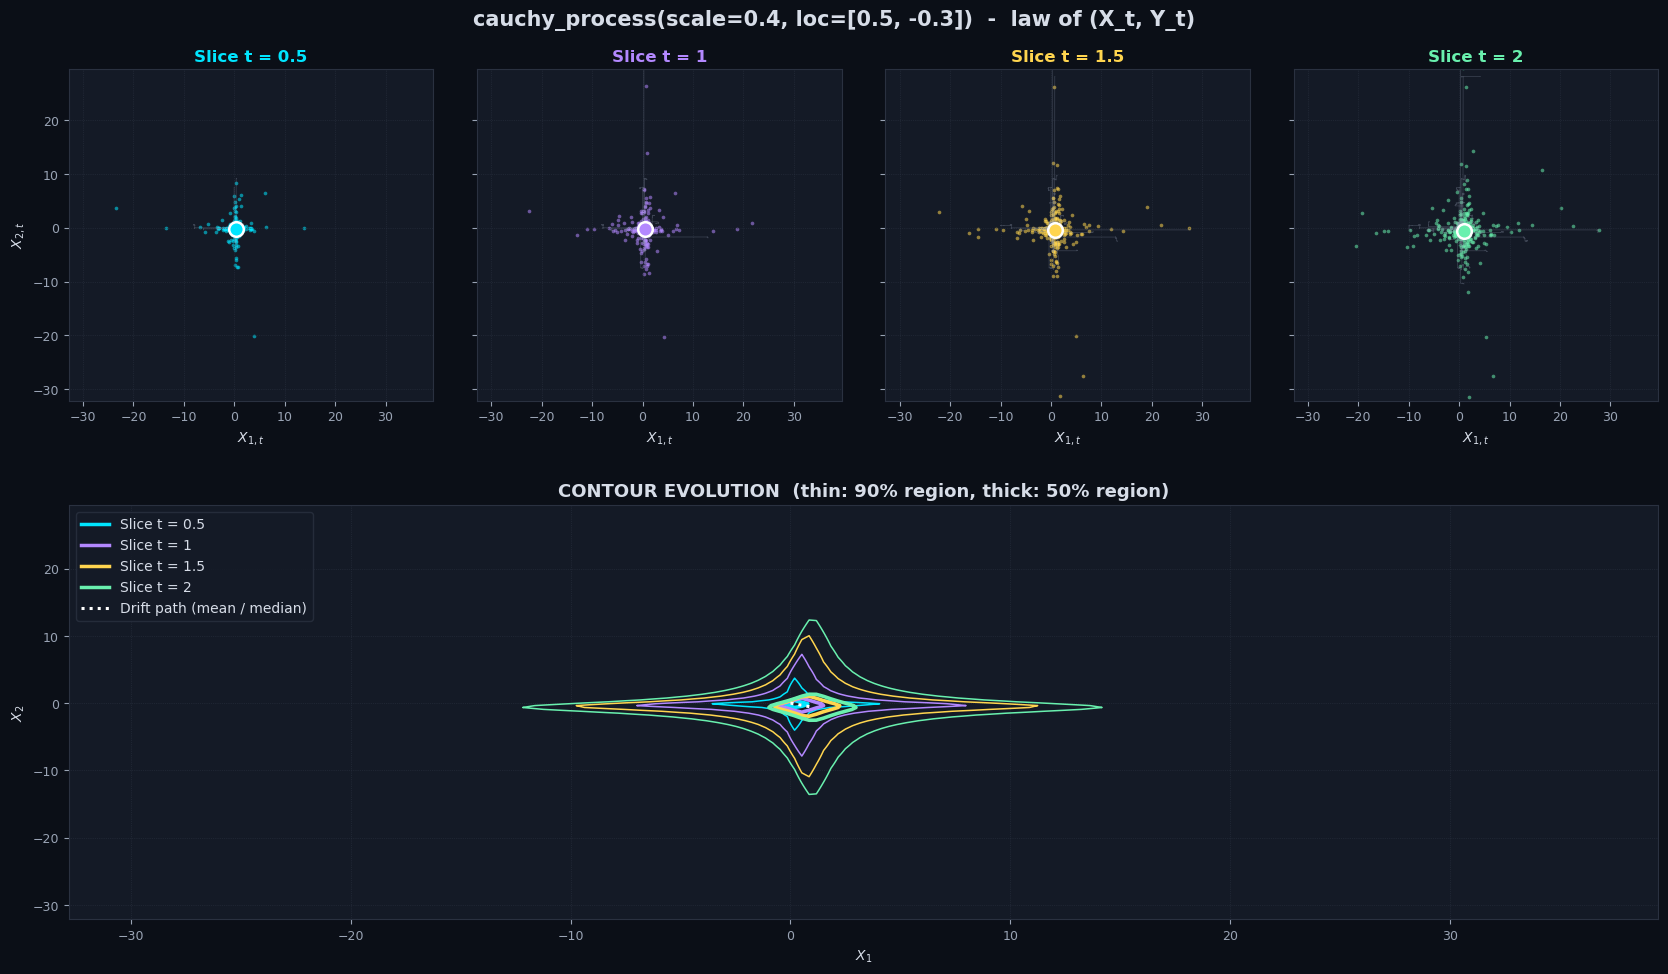

In [18]:
m_cauchy = rd.cauchy_process(scale=[0.4, 0.4], loc=[0.5, -0.3], seed=15)
fig = m_cauchy.analyze(t=4, T=2.0, seed=15)

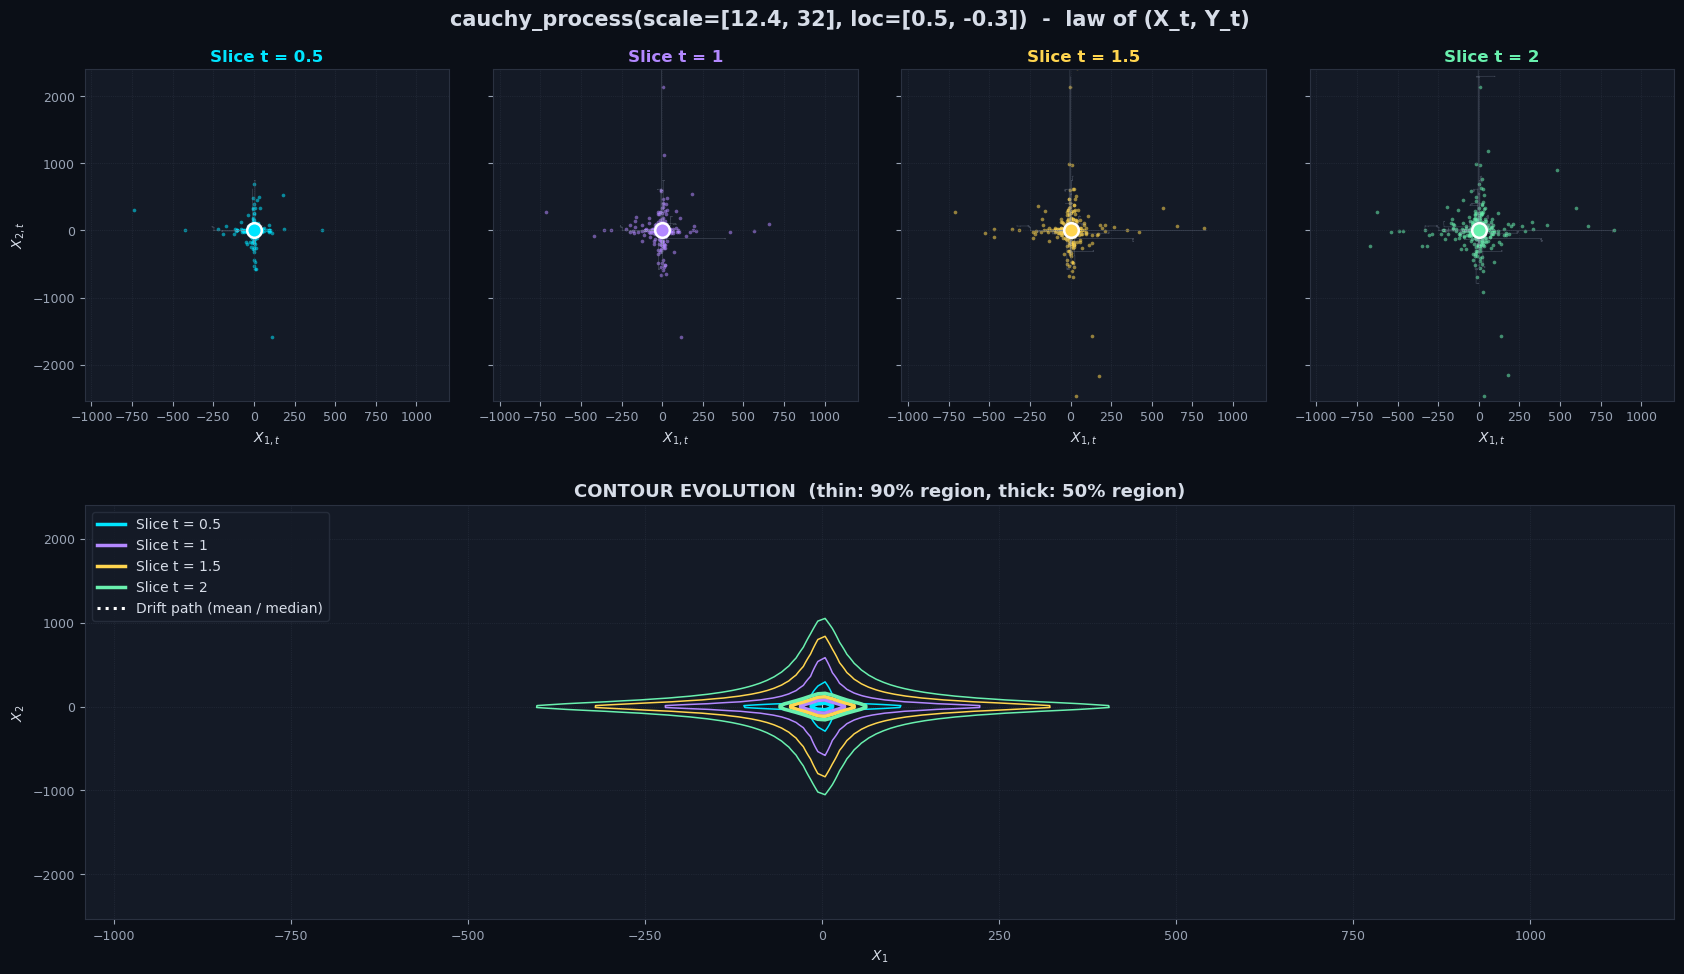

In [19]:
m_cau = rd.cauchy_process(scale=[12.4, 32], loc=[0.5, -0.3], seed=15)
fig = m_cau.analyze(t=4, T=2.0, seed=15)

Note that even though both processes look the same, the spread for the first is $[-30, 30]^2$ whereas the spread for the second is $[-1000, 1000]^2$, and that is because we simply altered the scale.

---
## 5. Rare-Event Importance Sampling (`rare`)

Estimating tail probabilities like $\mathbb{P}(X^1_T > K)$ via naive Monte Carlo suffers extreme variance when $K$ is several standard deviations away. `m.rare(K, T=...)` automatically solves for the optimal Esscher tilt $\theta_1^*$ that centers $\mathbb{Q}_\theta$ right on the threshold $K$, reweights paths by $d\mathbb{P}/d\mathbb{Q}_\theta$, and plots the convergence with 95% confidence bands.

P(X^1_T > 3.5)  exact = 3.1671e-05   tilt theta_1 = 4.0000
  naive MC      : 0.0000e+00 +- 0.00e+00
  importance S. : 3.1915e-05 +- 5.95e-07


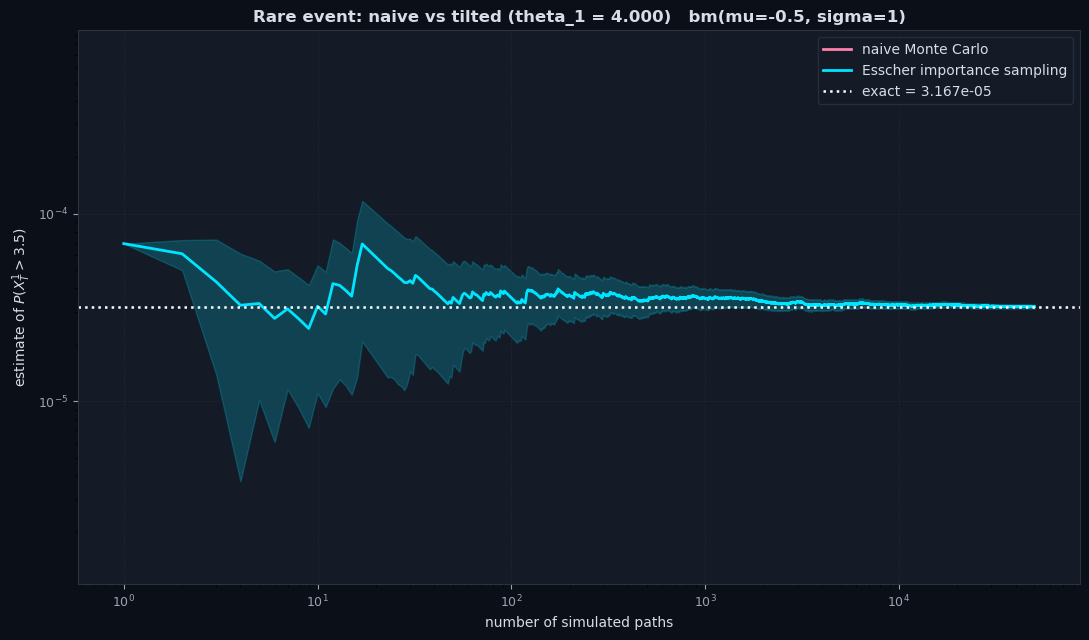

In [20]:
m_tail = rd.bm(mu=-0.5, sigma=1.0, seed=20)
res_bm = m_tail.rare(K=3.5, T=1.0, n_max=50_000, seed=20)

P(X^1_T > 8)  exact = 7.9875e-05   tilt theta_1 = 1.2500
  naive MC      : 6.0000e-05 +- 6.79e-05
  importance S. : 8.0311e-05 +- 2.21e-06
  variance reduction ~ x947


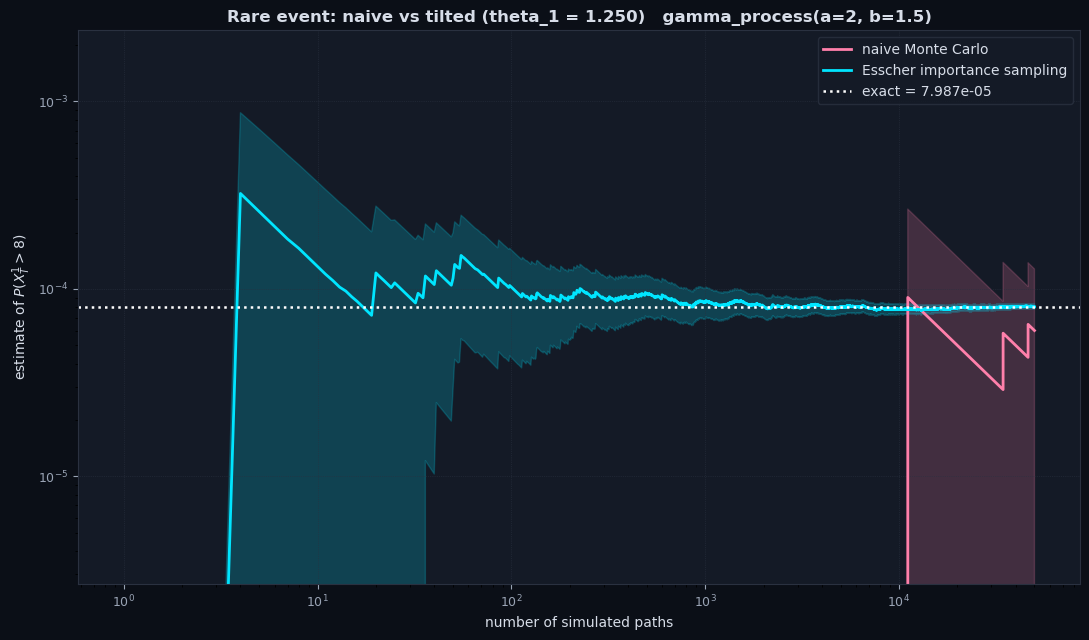

In [21]:
# Rare event on a Gamma subordinator (theta_1 stays strictly below rate b = 1.5)
m_gam_tail = rd.gamma_process(a=2.0, b=1.5, seed=21)
res_gam = m_gam_tail.rare(K=8.0, T=1.0, n_max=50_000, seed=21)

---
## 6. Interactive 3-D Law Viewer (`plot_law` & `tilt`)

### How `plot_law` and `tilt` Run in JupyterLab
* `plot_law()` and `tilt()` launch a local Dash server in a background thread (`block=False` automatically inside IPython/Jupyter) and print a URL (`http://127.0.0.1:<port>`).
* Passing `open_browser=False` keeps it from popping open a separate browser tab automatically; you can either click the printed URL or embed the live viewer directly inside a notebook cell using `IPython.display.IFrame`.
* Passing `time=t` with a custom grid like `t = np.linspace(0, 20, 45)` lets you explore long horizons (whereas `time_slice` defaults to `T=1.0`).
* Use `width` and `height` (default `width=1900, height=950`) to resize the viewer to fit your screen resolution.

### 6.1 Discrete 2-D Poisson Process
Watch discrete probability spikes step across the $(X_t, Y_t)$ lattice over a long horizon $t \in [0, 20]$.
```python
t = np.linspace(0, 20, 45)
m_pois_3d = rd.poisson(rate=[0.4, 0.7], seed=30)

app_pois = m_pois_3d.plot_law(time=t, width=1300, height=550, n=25, open_browser=False)
```
If you to run the rendering at default, just go with the following:
```python
t = np.linspace(0, 20, 45)
m_pois_3d = rd.poisson(rate=[0.4, 0.7], seed=30)

app_pois = m_pois_3d.plot_law(time=t, n=25)
```

### 6.2 Correlated Discounted Stocks with Measure Toggle ($\mathbb{P}, \mathbb{Q}, \mathbb{Q}_1, \mathbb{Q}_2$)
Switch live between the physical measure $\mathbb{P}$, risk-neutral measure $\mathbb{Q}$, and stock-numeraire measures $\mathbb{Q}_1, \mathbb{Q}_2$, and compare closed-form densities against Radon–Nikodym reweighted paths.
```python
t = np.linspace(0, 20, 45)
m_stocks_3d = rd.stocks(mu=[0.09, 0.07], sigma=[0.22, 0.28], r=0.02, rho=0.65, seed=31, verbose=False)

app_stocks = m_stocks_3d.plot_law(time=t, n=25)
```

### 6.3 Correlated Brownian Motion with Interactive Esscher Tilt Slider (`tilt`)
Drag the horizontal Esscher $\theta$ slider to tilt the drift in real time, or click **snap to drift-free $\theta^*$** to remove drift along the diagonal.
```python
m_tilt_3d = rd.bm(mu=[0.8, 0.5], sigma=[1.0, 1.0], rho=0.4, seed=32)

app_tilt = m_tilt_3d.tilt(time_slice=12, T=2.0, n=25)
```

### 6.4 2-D Brownian Bridge: Pinched Density Evolution
Scrub through time to watch the Gaussian surface start at $(0, 0)$, billow outward at mid-horizon $t = T/2$, and sharpen back into a spike at `end = (2.0, -1.5)` as $t \to T$.
```python
m_bridge_3d = rd.bm_bridge(sigma=[1.0, 1.2], end=(2.0, -1.5), T=2.0, seed=33)

app_bridge = m_bridge_3d.plot_law(time_slice=16, T=2.0, n=30)
```

### 6.5 Gamma Subordinator with Esscher Rate Tilting (`tilt`)
A pure-jump subordinator restricted to the positive quadrant $[0, \infty)^2$: tilting by $\theta < b$ shifts the exponential decay rate $b \mapsto b - \theta$ and stretches the upper-right tail.
```python
m_gamma_3d = rd.gamma_process(a=[2.0, 2.5], b=[1.8, 1.8], seed=34)

app_gamma = m_gamma_3d.tilt(time_slice=15, T=3.0, theta_range=(-1.5, 1.2), n=25)
```

### 6.6 Heavy-Tailed Cauchy Process (`cauchy_process`)
Explore a stable Lévy process with infinite variance and occasional extreme jumps (note that calling `.tilt()` on `cauchy_process` prints an informative warning because its MGF does not exist).
```python
m_cauchy_3d = rd.cauchy_process(scale=[0.4, 0.4], loc=[0.3, -0.2], seed=35)

app_cauchy = m_cauchy_3d.plot_law(time_slice=15, T=2.0, n=25)
```

### 6.7 Girsanov Likelihood-Ratio Process $Z_t = d\mathbb{Q}/d\mathbb{P}$ (`rd.lr`)
Visualize the 1-D Radon–Nikodym martingale $Z_t$ in real time alongside its evolving density, running mean $\mathbb{E}^{\mathbb{P}}[Z_t] \approx 1$, `ESS`, and KL divergence rate.
```python
z = rd.lr(rd.bm(mu=[0.7, 0.4], sigma=1.0, seed=36), rd.bm(mu=[0.0, 0.0], sigma=1.0, seed=36))

app_lr = z.plot_law(time_slice=15, T=3.0, n=30)
```